In [1]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Myoelectric paper page 9 - LHS of page
# "obtain a unique solution to the system of Eq. (2), we constrain potentials v to have a zero sum"
# This is how they ensure uniqueness
# Implement the same instead of the one we chose here: phi[0] = 0

In [3]:
# Adjust the forward problem to actually make use of Neural Physics approach
# Let the stencil coeffecients be the filter weights

## Collapsed Maxwell Equations

Conductivity-weighted Poisson problem with homogeneous Neumann boundary condition (perfectly insulating boundaries):

$$
\begin{cases}
\nabla \cdot (\sigma \nabla \phi) = -I & \text{in } \Omega \\[4pt]
\sigma \dfrac{\partial \phi}{\partial \mathbf{n}} = \sigma \nabla \phi \cdot \mathbf{n} = 0 & \text{on } \partial\Omega
\end{cases}
$$

The current source density $I(x)$ is interpreted as the volume density of current entering or leaving the extracellular medium at position $x \in \Omega$. A
negative CSD corresponds to current leaving the extracellular medium
(due to the bre transmembrane currents) and is thus conventionally
called a sink. Likewise, current entering the extracellular medium is
called a source (excerpt from the paper below)

**Reference**: <br>
maksymenko2023, <br>
author  = {K. Maksymenko and A. K. Clarke and I. {Mendez Guerra} and S. Deslauriers-Gauthier and D. Farina}, <br>
title   = {A myoelectric digital twin for fast and realistic modelling in deep learning}, <br>
journal = {Nature Communications}, <br>
volume  = {14}, <br>
pages   = {1600}, <br>
year    = {2023}, <br>
doi     = {10.1038/s41467-023-37238-w}


In this notebook, for simplicity we shall consider the tissue conductivity tensor $\sigma$ to be constant (homogeneous and isotropic case), so it can be factored out. <br>
The differential equation itself can never be homogeneous as we require $I \neq 0$, where $I$ is the current source density. In the inverse problem, this is the parameter we aim to retrieve given $\phi$ (our data) from the sEMG readings.

Therefore, our equation simplifies to:
$$
\sigma \nabla^2 \phi(x) = -I(x)
$$

where $I \neq 0$, $x \in \mathbb{R}^n, \sigma \in \mathbb{R}^{n \times n}$ for $n=1,2,3$ depending on which spatial domain we are considering for the demo.

## 1D Demo

We shall go with a toy demo in 1D ($\Omega = \mathbb{R}$) despite it having no physical meaning - good for understanding. <br>

In [4]:
# 1D domain setup

# reproducibilty
# inverse problem involves optimisation from an initial guess
torch.manual_seed(42)
np.random.seed(42)

# double precision needed throughout
# float32 causes round-off errors in the gradient when we differentiate for the inverse problem
torch.set_default_dtype(torch.float64)

# 1D domain - [0, L]
L = 1.0
N = 65 # number of grid points

# vertex-centred grid
x = torch.linspace(0.0, L, N)
assert torch.Tensor.dim(x) == 1 # we are considering the 1D case, so x is an element of R
h = x[1] - x[0]

print(f"Domain [0, {L}] discretised with N = {N} points")
print(f"Grid spacing h = {h.item():.6f}  (= L/(N-1) = {L/(N-1):.6f})")
print(f"x has shape {x.shape}")
print(f"First 5 entries of x, x[:5]  = {x[:5].tolist()}")

Domain [0, 1.0] discretised with N = 65 points
Grid spacing h = 0.015625  (= L/(N-1) = 0.015625)
x has shape torch.Size([65])
First 5 entries of x, x[:5]  = [0.0, 0.015625, 0.03125, 0.046875, 0.0625]


Here in 1D, the continuous problem is: <br> $\sigma \phi''(x) = -I(x)$ on $[0, L]$, where $x, \sigma \in \mathbb{R}$ <br> subject to homogeneous Neumann bounday conditions $\phi'(0) = \phi'(L) = 0$. <br> For further simplicity, we will take $\sigma = 1$ when we implement the discretisation in the cell below.

We will discretise the operator $\phi''$ with the 3-point second-order, central difference scheme. <br> For an interior point node i: <br> $\phi''(x_i) \approx \frac{\phi(x_{i+1}) - 2\phi(x_{i}) + \phi(x_{i-1})}{h^2}$. <br> So, the interior rows of the operator are the stencil $[1, -2, 1] / h^2$. These are the weights in the kernel in the convolutional layers (Neural Physics approach).

We will now implement this below:


In [5]:
# CNN layer carries a classical numerical operator exactly
kernel = torch.tensor([1, -2, 1], dtype=torch.float64) / h**2
weight = kernel.view(1, 1, 3) # Conv1d expects a weight tensor of shape (out_channels, in_channel, kernel)

print(f"Kernel has shape {kernel.shape}.")
print(f"Weight has shape {weight.shape}.") # (out_channels=1, in_channels=1, kernel=3)

Kernel has shape torch.Size([3]).
Weight has shape torch.Size([1, 1, 3]).


In [6]:
def laplacian(phi):
    """
    sigma * d2/dx2 (sigma = 1) applied as a convolution.

    Reflect padding sets the ghost nodes phi[-1] = phi[1] and phi[N] = phi[N-2],
    which is exactly the homogeneous Neumann ghost-node closure. So the boundary
    rows match the dense operator A bit-for-bit, with no special-casing needed.
    """
    phi_in  = phi.view(1, 1, N)
    phi_pad = F.pad(phi_in, (1, 1), mode="reflect") # length N+2
    return F.conv1d(phi_pad, weight).view(N) # length N, equivalent to the dense A @ phi we had before

# Jacobi diagonal
# every row of the operator has centre weight -2/h^2 (sigma = 1),
# so D = (-2/h**2) I - inverse of a diagonal matrix is the reciprocal of the diagonal entries
D_inv = 1.0 / weight[0, 0, 1] # = -h^2 / 2

sigma = 1.0 # tissue conductivity - constant scalar

(May get rid of cell)

Note $\phi_i$ is shorthand for $\phi(x_i)$, where $i$ is the $i-\text{th}$ grid point. <br> For the Neumann boundary condition we add a fictitious ghost node $\phi_{-1}$ at $x = -h$. A centred finite-difference approximation of the Neumann BC $\phi'(0) = 0$ gives:

$$\phi'(0) \approx \frac{\phi_1 - \phi_{-1}}{2h} = 0 \implies \phi_{-1} = \phi_1$$

Substituting into the $i = 0$ stencil:

$$\frac{\phi_{-1} - 2\phi_0 + \phi_1}{h^2} = \frac{2\phi_1 - 2\phi_0}{h^2}$$

so the first row of the discrete operator becomes $\dfrac{1}{h^2}[-2,\ 2,\ 0,\ \ldots]$.

We apply the same ghost node argument at the right boundary, which gives $\phi_N = \phi_{N-2}$. Hence, the last row of the discrete operator becomes $\dfrac{1}{h^2}[\ldots,\ 0,\ 2,\ -2]$.

(**Important note**) We have a problem of there being a constant vector in the null space (we can see from above). If $\phi$ solves the system, so does $\phi + c$ for any constant $c$. The Neumann problem only determines $\phi$ up to that additive constant. We have to resolve this later for the inverse problem to recover $I$ uniquely.

Now we discuss source term $I_{\text{field}}(x)$ and the solvability condition (zero-mean).

Why $I_{\text{field}}(x)$ must be zero-mean:
$A$ is singular. A singular system $A\phi = b$ has a solution only if $b$ is orthogonal to the left of the null space of $A$. That left null vector is the trapezoidal-weight vector $w = (1, 2, 2, ..., 2, 1)$ and $w \cdot b$ is the trapezoidal-rule integral of b, up to the factor $h / 2$. <br> With $b = -I_{\text{field}}$, the condition $w \cdot b$ becomes $\int I_{\text{field}}(x) \,dx = 0$. In the discrete case this is $w \cdot I = 0, \forall I \neq 0$
<br> *Physics interpretation*: this is current conservation - in an insulated domain the net injected current must be zero, (every source must be cancelled with a sink).

A current dipole - unit source at one interior node and a unit sink at another.
This is the elementary physical source in a volume conductor - a muscle fibre's transmembrane current integrates to zero along its length - zero mean condition falls out naturally.

Note to self - understand Biophysics techincals/domain knowledge better!!

In [7]:
w = torch.full((N,), 2.0); w[0] = 1.0; w[-1] = 1.0
ones = torch.ones(N)

In [8]:
def zero_mean_condition(v):
    """
    Enforce w·v = 0 (charge conservation).
    Removes the trapezoidal-weighted mean
    A free source field would generically violate solvability, leaving
    A phi = b with no solution a.
    this projection makes the forward map well-defined for any input field.
    """
    return v - (w @ v) / (w @ ones) * ones

In [9]:
def forward(I_field, jacobi_iterations=5000):
    b = zero_mean_condition(I_field)
    phi = torch.zeros(N)
    for _ in range(jacobi_iterations):
        phi = phi + D_inv * (b - laplacian(phi))  # Jacobi: phi += D^{-1}(b - A·phi)
    return phi - phi[0]  # uniquness fix

# phi is only defined up to an additive constant due to A·1 = 0 (see earlier)
# operator is still singular and the source zero-mean; 
# this only selects the additive constant in the one-parameter family phi + c by subtracting the value at node 0

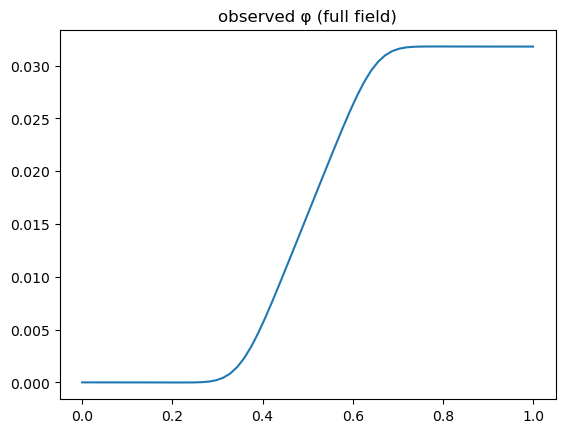

In [11]:
# Realisitc source field this time

g1 = torch.exp(-((x - 0.35) / 0.06) ** 2)
g2 = torch.exp(-((x - 0.65) / 0.06) ** 2)

assert len(x) == len(g1) == len(g2) == N

I_true  = zero_mean_condition(g1 - g2)
assert np.isclose(I_true.sum(), 0.0) # check zero mean property - every source must be sunk

phi_obs = forward(I_true).detach() # synthetic electrode measurements - generated from our ground truth parameter I

# plot our observed electrode measurement phi
plt.plot(x, phi_obs)
plt.title('observed φ (full field)');

In [20]:
# Discrete operator for sigma * phi''

sigma = 1.0 # tissue conductivity - constant scalar

# second derivative discretisation matrix (second-difference) D2 i.e. D2 @ phi = phi''
D2 = torch.zeros(N, N) # initialise matrix

# interior rows: [1, -2, 1]
# D2 is a tridiagonal matrix (if we didn't have BCs)
for i in range(1, N-1): # N points - indices are 0, 1,..., N-1, so, the two boundary nodes are index 0 and N-1
    D2[i, i-1] = 1.0
    D2[i, i] = -2.0
    D2[i, i+1] = 1.0


# Homogeneous Neumann boundary conditions via ghost nodes

# left boundary
D2[0, 0] = -2.0
D2[0, 1] = 2.0

# mirror at the right boundary
D2[N - 1, N - 1] = -2.0
D2[N - 1, N - 2] =  2.0


# Now we set up the full operator

# apply the 1/h^2 scaling
D2 = D2 / (h**2)

# A is the full matrix operator for sigma * phi''
A = sigma * D2

assert laplacian(phi_obs).shape == (A @ phi_obs).shape # check the shapes match

assert np.allclose(A @ phi_obs, laplacian(phi_obs)) # verify the dense representation is the same as the convolutional approach - they are the same tensor

Now it's time for the forward solve, where we will use a simple Jacobi iterative solver initially (before we try more sophisticated techniques such as multigrid).

We solve $A \phi = b$, where we derived $A$ earlier and $b = I_{\text{field}}$.

Jacobi splitting A = D + L + U gives us the following update (recall Inversion and Optimisation), <br>
$\phi_{k+1} = \phi_k + D^{-1} r_k , \text{where }  r_k = b - A \phi_k $.

In this scenario, every diagonal entry of $A$ equals $-2\sigma/h^2 = -2/h^2$ because we set $\sigma = 1$. Therefore, $D = (-2/h^2)I$ is a scalar multiple of the identity matrix.

In [21]:
# Inverse problem

# we attempt to recover I_true from our observed phi 

I_hat = torch.zeros(N, requires_grad=True) # initialise our initial guess at 0
lr = 0.2
optimiser = torch.optim.Adam([I_hat], lr=lr)

I_true_norm = torch.linalg.norm(I_true).item() # compute this once outside the loop
loss_history, field_error_history = [], []
max_iters = 250
for i in range(max_iters):
    optimiser.zero_grad() # clear gradients for the next iteration
    phi_pred = forward(I_hat) # differentiable forward solve
    loss = 0.5 * ((phi_pred - phi_obs) ** 2).sum() # full field data misfit
    loss.backward() # calculate gradients by backpropagating using Jacobi
    optimiser.step() # Adam update of I_hat (update our parameter)

    loss_history.append(loss.item())
    field_error = (torch.linalg.norm(zero_mean_condition(I_hat.detach()) - I_true) # we project I_hat to have zero mean to prevent the trapezoidal mean drift which is caused by too many Adam iterations
                   / I_true_norm).item()
    field_error_history.append(field_error)
    if i % 50 == 0:
        print(f" step {i:3d}: data loss = {loss.item():.2e}   rel field err = {field_error_history[-1]:.3e}")

 step   0: data loss = 1.47e-02   rel field err = 8.398e-01
 step  50: data loss = 2.06e-05   rel field err = 7.771e-01
 step 100: data loss = 5.10e-06   rel field err = 7.676e-01
 step 150: data loss = 4.01e-06   rel field err = 6.998e-01
 step 200: data loss = 3.12e-06   rel field err = 6.235e-01


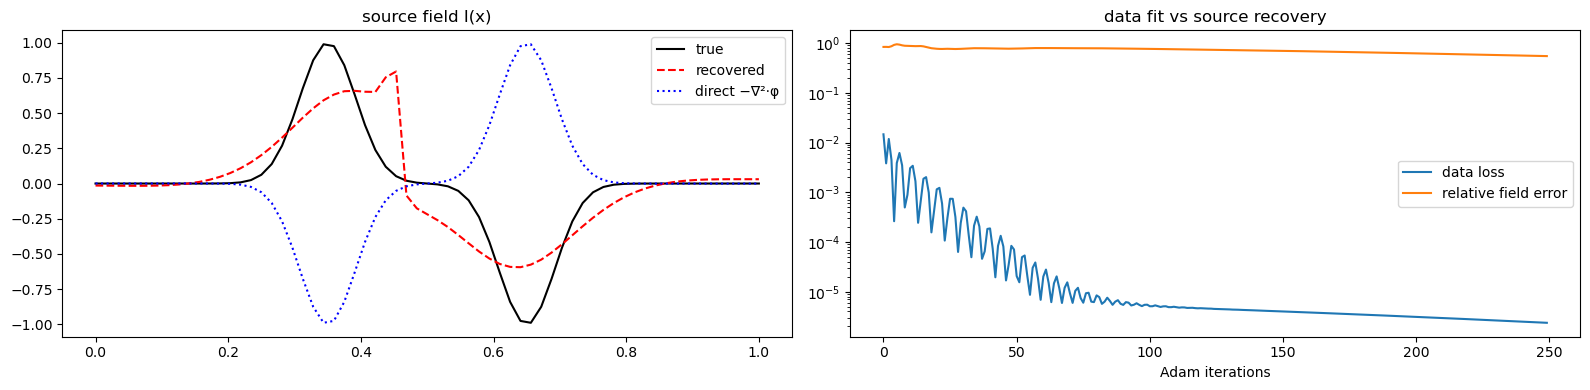

In [22]:
# analytic plots
recovered_field = zero_mean_condition(I_hat.detach())
fig, ax = plt.subplots(1, 2, figsize=(16, 4))

ax[0].plot(x, I_true, 'k', label='true')
ax[0].plot(x, recovered_field, 'r--', label='recovered')
ax[0].plot(x, -laplacian(phi_obs), 'b:', label='direct −∇²·φ')
ax[0].legend();
ax[0].set_title('source field I(x)')

ax[1].semilogy(loss_history, label='data loss')
ax[1].semilogy(field_error_history, label='relative field error')
ax[1].legend()
ax[1].set_xlabel('Adam iterations')
ax[1].set_title('data fit vs source recovery')

plt.tight_layout()
plt.show();